# **The Monty Hall Problem**

**The Mathematics of Choice, Information and Probability**
___

**Statistical Simulation | Probability Fundamentals**
___

Three doors. One car. Two goats.
A contestant is asked to choose one of three closed doors. Behind one door is a car, while the other two conceal goats.
After the initial selection, the host—who knows what is behind every door—opens one of the remaining doors, deliberately revealing a goat.

The contestant is then offered a choice:

**Stay with the original door, or switch to the other unopened door?**

At first glance, both strategies may appear equally promising. After all, there are now only two unopened doors, and the car must be behind one of them.
However, the host's action is not random. It is constrained by knowledge of the car's location.
This creates a probability problem in which the information revealed by another participant changes how the available choices should be evaluated.

This notebook investigates both strategies mathematically and through a large-scale Monte Carlo experiment.

**Objective:** Determine which strategy maximizes the probability of winning the car.

___

## **1. Experimental Setup**

We consider a game consisting of three doors:

- One door conceals a car.
- The other two doors conceal goats.
- The contestant initially selects exactly one door.
- The host knows the location of the car.
- The host opens exactly one unselected door, always revealing a goat.
- The contestant must then decide whether to retain the initial selection or switch to the remaining unopened door.

### **Rules governing the host**

The host's behaviour is an essential part of the experiment:

1. The host never opens the contestant's initially selected door.
2. The host never reveals the car.
3. The host always opens a door containing a goat.
4. If both unselected doors contain goats, the host chooses randomly between them.

The fourth rule specifies how the host behaves when both possible doors can be opened. It completes the experimental model.

### **Competing strategies**

**Strategy A - Stay**

The contestant retains the door selected initially.

**Strategy B - Switch**

The contestant abandons the initial selection and chooses the only other unopened door.

### **Definition of success**

A trial is considered successful if the contestant's final selection contains the car.
We will evaluate both strategies using exactly the same simulated game conditions so that their performance can be compared directly.

___

## **2. Mathematical Model**

Let:

- \(C\) represent the door containing the car.
- \(P\) represent the contestant's initial selection.
- \(H\) represent the door opened by the host.

The car and initial selection are independently assigned among the three doors.

Therefore:

$$
P(C=P)=\frac{1}{3}
$$

The probability that the initial selection contains a goat is:

$$
P(C\neq P)=\frac{2}{3}
$$

### **Strategy A: Staying with the initial selection**

The contestant wins only when the initial selection is correct.

$$
P(\text{Win}\mid Stay)=P(C=P)
$$

$$
\boxed{P(\text{Win}\mid Stay)=\frac{1}{3}}
$$

### **Strategy B: Switching to the remaining unopened door**

The contestant wins when the initial selection is incorrect.

If the initial selection is wrong, the car must be behind one of the other two doors. Since the host is required to reveal a goat, the remaining unopened door necessarily contains the car.

Therefore:

$$
P(\text{Win}\mid Switch)=P(C\neq P)
$$

$$
\boxed{P(\text{Win}\mid Switch)=\frac{2}{3}}
$$

### **Theoretical comparison**

| Strategy | Winning probability | Losing probability |
|---|---:|---:|
| Stay | \(1/3\) = 33.33% | \(2/3\) = 66.67% |
| Switch | \(2/3\) = 66.67% | \(1/3\) = 33.33% |

Under the specified host rules, switching doubles the probability of winning.
The simulation below will independently test this theoretical prediction.

**Import libraries and configure visualisation**

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [29]:
COLORS = {
    "background": "#0B1020",
    "panel": "#121A2B",
    "text": "#F1F5F9",
    "muted": "#94A3B8",
    "cyan": "#22D3EE",
    "coral": "#FB7185",
    "gold": "#FBBF24",
    "green": "#34D399",
    "grid": "#293449"
}

plt.rcParams.update({
    "figure.facecolor": COLORS["background"],
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "savefig.facecolor": COLORS["background"],
    "axes.facecolor": COLORS["panel"],
    "axes.edgecolor": COLORS["grid"],
    "axes.labelcolor": COLORS["text"],
    "axes.titlecolor": COLORS["text"],
    "axes.titleweight": "bold",
    "axes.labelweight": "normal",
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"],
    "text.color": COLORS["text"],
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "axes.titlepad": 18,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": COLORS["grid"],
    "grid.alpha": 0.45,
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "legend.frameon": True,
    "legend.facecolor": COLORS["panel"],
    "legend.edgecolor": COLORS["grid"],
    "legend.framealpha": 0.92,
    "legend.fontsize": 9.5
})

**Defining the game parameters**

In [18]:
# Door labels
DOORS = np.array([1, 2, 3])

# Number of simulated games
N_SIMULATIONS = 1_000_000

# Reproducibility
rng = np.random.default_rng(42)

print(f"Available doors: {DOORS}")
print(f"Total simulated games: {N_SIMULATIONS:,}")

Available doors: [1 2 3]
Total simulated games: 1,000,000


___

## **3. Monte Carlo Simulation Design**

To evaluate both strategies, we will simulate one million independent rounds of the Monty Hall game.
Each round follows the same sequence of events.

**Step 1 - Place the car**

The car is randomly assigned to one of the three doors.

**Step 2 - Initial selection**

The contestant randomly selects one door without knowing where the car is located.

**Step 3 - Host intervention**

The host identifies the available unselected doors containing goats and opens exactly one of them.
If both unselected doors contain goats, the host randomly chooses which one to open.

**Step 4 - Final decision**

Two outcomes are evaluated from the same initial game:

- Stay: Retain the original selection.
- Switch: Select the remaining unopened door.

**Step 5 - Record the outcomes**

For each strategy, we record whether the final selection contains the car.

### **Experimental design consideration**

Both strategies are evaluated on the same simulated rounds rather than on two separately generated populations.
This ensures that the comparison is paired: each strategy faces the same car placement, initial selection and host decision.
It also makes the comparison easier to interpret because differences in performance cannot be attributed to different randomly generated game conditions.

**Stimulate the game**

In [19]:
# Generate the car location for every game
car_doors = rng.integers(1, 4, size=N_SIMULATIONS)

# Generate the contestant's initial selection
initial_picks = rng.integers(1, 4, size=N_SIMULATIONS)

# Identify doors that the host is allowed to open
# A door is eligible if it is neither the initial pick nor the car door.

host_candidates = (
    (DOORS[None, :] != initial_picks[:, None])
    &
    (DOORS[None, :] != car_doors[:, None])
)

# Count eligible doors for each game
candidate_counts = host_candidates.sum(axis=1)

# Randomly choose an eligible door.
# If only one goat door is eligible, it is selected automatically.
# If two goat doors are eligible, one is chosen randomly.

random_values = rng.random(N_SIMULATIONS)

candidate_indices = np.argmax(
    np.cumsum(host_candidates, axis=1)
    > (random_values[:, None] * candidate_counts[:, None]),
    axis=1
)

host_opened = DOORS[candidate_indices]

# Strategy A: Stay with the initial selection
stay_wins = initial_picks == car_doors

# Strategy B: Switch to the only remaining unopened door
switch_picks = (
    6 - initial_picks - host_opened
)

switch_wins = switch_picks == car_doors

# Store the results
simulation_results = pd.DataFrame({
    "Car Door": car_doors,
    "Initial Pick": initial_picks,
    "Host Opened": host_opened,
    "Switch Pick": switch_picks,
    "Stay Win": stay_wins,
    "Switch Win": switch_wins
})

simulation_results.head(10)

,Car Door,Initial Pick,Host Opened,Switch Pick,Stay Win,Switch Win
0,1,3,2,1,False,True
1,3,2,1,3,False,True
2,2,3,1,2,False,True
3,2,1,3,2,False,True
4,2,2,3,1,True,False
5,3,3,1,2,True,False
6,1,2,3,1,False,True
7,3,2,1,3,False,True
8,1,3,2,1,False,True
9,1,3,2,1,False,True


___
**Validate the simulation logic**

Before interpreting the result, we'll verify that the simulated games obey the rules.

In [20]:
# The host must never open the initial selection
check_1 = np.all(host_opened != initial_picks)

# The host must never reveal the car
check_2 = np.all(host_opened != car_doors)

# Switching must always select the only remaining unopened door
check_3 = np.all(
    (switch_picks != initial_picks)
    & (switch_picks != host_opened)
)

# The final switching choice must be a valid door
check_4 = np.all(np.isin(switch_picks, DOORS))

validation_results = pd.DataFrame({
    "Validation": [
        "Host never opens the initial selection",
        "Host never reveals the car",
        "Switch selects the remaining unopened door",
        "Switch selection is always a valid door"
    ],
    "Passed": [
        check_1,
        check_2,
        check_3,
        check_4
    ]
})

validation_results

,Validation,Passed
0,Host never opens the initial selection,True
1,Host never reveals the car,True
2,Switch selects the remaining unopened door,True
3,Switch selection is always a valid door,True


**Simulation Validation**

_Before examining the winning probabilities, the simulation logic was subjected to four validation checks. All checks must pass for the experiment to represent the intended Monty Hall game._

_In particular, the host must never reveal the car or open the contestant's initial selection.The switching strategy must also select the only remaining unopened door._

_These constraints are essential. A simulation that allows the host to reveal the car, or chooses a door without following the host's rules, would represent a different probability experiment._

_As the validation is successful, it establishes that generated outcomes follow the specified game mechanics._

___
**Calculate the winning Probability**


In [21]:
# Count successful games
stay_successes = np.sum(stay_wins)
switch_successes = np.sum(switch_wins)

# Estimate winning probabilities
stay_probability = stay_successes / N_SIMULATIONS
switch_probability = switch_successes / N_SIMULATIONS

# Calculate losing probabilities
stay_losses = N_SIMULATIONS - stay_successes
switch_losses = N_SIMULATIONS - switch_successes

# Theoretical probabilities
theoretical_stay = 1 / 3
theoretical_switch = 2 / 3

# Create the comparison table
strategy_results = pd.DataFrame({
    "Strategy": ["Stay", "Switch"],
    "Successful Games": [
        stay_successes,
        switch_successes
    ],
    "Unsuccessful Games": [
        stay_losses,
        switch_losses
    ],
    "Simulated Probability": [
        stay_probability,
        switch_probability
    ],
    "Theoretical Probability": [
        theoretical_stay,
        theoretical_switch
    ]
})

strategy_results

,Strategy,Successful Games,Unsuccessful Games,Simulated Probability,Theoretical Probability
0,Stay,332838,667162,0.332838,0.333333
1,Switch,667162,332838,0.667162,0.666667


___
## **4. Initial Simulation Results**

The experiment evaluates one million rounds of the Monty Hall game.
For each round, both strategies are assessed using the same initial game conditions.
The resulting table reports the number of successful and unsuccessful games alongside the estimated and theoretical winning probabilities.

### What should we expect?

The theoretical model predicts:

$$
P(Win\mid Stay)=33.33\%
$$

$$
P(Win\mid Switch)=66.67\%
$$

The simulation should produce estimates close to these values, with small differences arising from random sampling.

The important comparison is not simply whether either strategy wins frequently. It is whether switching consistently produces a higher probability of success under the same experimental conditions.

**Calculate the advantage of switching**

In [22]:
# Absolute improvement from switching
switching_advantage = (
    switch_probability - stay_probability
)

# Relative improvement
relative_improvement = (
    (switch_probability / stay_probability) - 1
) * 100

# Difference between simulated and theoretical probabilities
stay_error = abs(stay_probability - theoretical_stay)
switch_error = abs(switch_probability - theoretical_switch)

strategy_diagnostics = pd.DataFrame({
    "Metric": [
        "Switching advantage (percentage points)",
        "Relative improvement from switching (%)",
        "Stay strategy absolute error",
        "Switch strategy absolute error"
    ],
    "Value": [
        switching_advantage * 100,
        relative_improvement,
        stay_error,
        switch_error
    ]
})

strategy_diagnostics

,Metric,Value
0,Switching advantage (percentage points),33.432400
1,Relative improvement from switching (%),100.446463
2,Stay strategy absolute error,0.000495
3,Switch strategy absolute error,0.000495


**Quantifying the Advantage of Switching**

_The difference between the two estimated winning probabilities measures the practical advantage of switching.The theoretical difference is:_

$$
\frac{2}{3}-\frac{1}{3}=\frac{1}{3}
$$

_Therefore, switching provides an absolute improvement of approximately:_

$$
\boxed{33.33\text{ percentage points}}
$$

_In relative terms:_

$$
\frac{2/3-1/3}{1/3}\times100=100\%
$$

_Under the specified rules, switching doubles the probability of winning compared with staying.This is a substantial difference produced not by changing the number of available doors, but by using the information revealed through the host's constrained action._

___
## **5. Experimental Results and Interpretation**

The Monte Carlo experiment was conducted over **1,000,000 independent games**, with both strategies evaluated under identical initial conditions.

### Observed results

| Strategy | Successful games | Winning probability | Theoretical probability |
|---|---:|---:|---:|
| Stay | 332,838 | 33.2838% | 33.3333% |
| Switch | 667,162 | 66.7162% | 66.6667% |

The simulation closely reproduces the theoretical predictions.

For the staying strategy:

$$
\hat P(Win\mid Stay)=\frac{332838}{1000000}=0.332838
$$

For the switching strategy:

$$
\hat P(Win\mid Switch)=\frac{667162}{1000000}=0.667162
$$

The observed advantage of switching is:

$$
0.667162-0.332838=0.334324
$$

Therefore, switching increased the observed winning probability by **33.4324 percentage points**.The simulated switching strategy achieved approximately **100.45% more wins** than staying, relative to the number of wins obtained by staying.

### **An important observation**

The number of successful switching games is exactly equal to the number of unsuccessful staying games:

$$
667162=1000000-332838
$$

Similarly:

$$
332838=1000000-667162
$$

This relationship is not accidental.

Under the classical Monty Hall rules, the two strategies produce complementary outcomes in every individual game.The simulation therefore reveals a stronger mathematical relationship than merely observing that switching performs better on average.

___
## **6. Why Staying and Switching Are Exact Complements**

Consider the contestant's initial selection.
There are only two possibilities.

**Case 1: The initial selection contains the car.**

The contestant wins by staying.
Because the host must reveal a goat, the remaining unopened door also contains a goat. Switching therefore loses.

**Case 2: The initial selection contains a goat.**

The contestant loses by staying.
The host cannot reveal the car and cannot open the contestant's selected door. Consequently, the host must reveal the other goat.
The remaining unopened door contains the car, so switching wins.

These cases exhaust every possible game outcome.

| Initial selection | Stay | Switch |
|---|---|---|
| Car | Win | Lose |
| Goat | Lose | Win |

Therefore:

$$
\mathbb{1}_{StayWin}+\mathbb{1}_{SwitchWin}=1
$$

for every simulated game, where \(\mathbb{1}\) denotes an indicator variable.

Taking expectations:

$$
P(Win\mid Stay)+P(Win\mid Switch)=1
$$

Hence:

$$
P(Win\mid Switch)=1-P(Win\mid Stay)
$$

This identity holds exactly for the classical three-door game under the specified host rules.
It also explains why the two simulated probabilities always sum to one, regardless of the number of trials.

**Verify Complementarity**

In [23]:
# Verify that the strategies produce opposite outcomes
complementary_outcomes = np.all(
    stay_wins != switch_wins
)

# Every game must produce exactly one winning strategy
exactly_one_winner = np.all(
    stay_wins.astype(int) + switch_wins.astype(int) == 1
)

# Verify the aggregate identity
probability_sum = stay_probability + switch_probability

print("Complementary outcome verification")
print("-" * 45)

print(f"Opposite outcomes in every game: {complementary_outcomes}")
print(f"Exactly one winning strategy: {exactly_one_winner}")
print(f"Sum of winning probabilities: {probability_sum:.6f}")

assert complementary_outcomes
assert exactly_one_winner
assert np.isclose(probability_sum, 1.0)

Complementary outcome verification
---------------------------------------------
Opposite outcomes in every game: True
Exactly one winning strategy: True
Sum of winning probabilities: 1.000000


_This is a useful validation because it tests a mathematical invariant of the simulation, rather than merely checking whether the estimated probabilities are close to the expected values._

___
## **7. Statistical Uncertainity**

In [24]:
# Standard errors of estimated winning probabilities
stay_se = np.sqrt(
    stay_probability * (1 - stay_probability) / N_SIMULATIONS
)

switch_se = np.sqrt(
    switch_probability * (1 - switch_probability) / N_SIMULATIONS
)

# Approximate 95% confidence intervals
z = 1.96

stay_ci = (
    stay_probability - z * stay_se,
    stay_probability + z * stay_se
)

switch_ci = (
    switch_probability - z * switch_se,
    switch_probability + z * switch_se
)

uncertainty_results = pd.DataFrame({
    "Strategy": ["Stay", "Switch"],
    "Estimated Probability": [
        stay_probability,
        switch_probability
    ],
    "Standard Error": [
        stay_se,
        switch_se
    ],
    "95% CI Lower": [
        stay_ci[0],
        switch_ci[0]
    ],
    "95% CI Upper": [
        stay_ci[1],
        switch_ci[1]
    ]
})

uncertainty_results

,Strategy,Estimated Probability,Standard Error,95% CI Lower,95% CI Upper
0,Stay,0.332838,0.000471,0.331914,0.333762
1,Switch,0.667162,0.000471,0.666238,0.668086


**Interpretation of Statistical Uncertainty**

_The standard error measures how much an estimated winning probability would typically fluctuate across repeated Monte Carlo experiments of the same size._

_With one million independent games, the standard error is approximately:_

$$
SE\approx0.000471
$$

_or **0.0471 percentage points**._

_The corresponding approximate 95% confidence interval has a margin of roughly:_

$$
1.96(0.000471)\approx0.000924
$$

_or **0.0924 percentage points**._

_Both simulated probabilities are consistent with their theoretical values.An important statistical detail is that the stay and switch estimates are not independent.They are computed from the same games, and every switching win corresponds to a staying loss.
Consequently, the two estimates are perfectly negatively correlated in this experiment._

_This paired structure must be considered when analysing the difference between strategies. Treating the estimates as independent would incorrectly describe their sampling uncertainty._

___
## **8. Monte Carlo convergence**

Now we'll use one visualization to answer a specific question:
How does the observed switching advantage stabilize as the number of games increases?
Instead of plotting two nearly mirrored curves, we'll plot the difference:

$$
\Delta_N=
\hat P_N(Win\mid Switch) -
\hat P_N(Win\mid Stay)
$$

The theoretical advantage is:

$$
\Delta=\frac{2}{3}-\frac{1}{3}=\frac{1}{3}
$$

This focuses directly on the decision we're investigating.

In [25]:
# Cumulative wins for each strategy
cumulative_stay = np.cumsum(stay_wins)
cumulative_switch = np.cumsum(switch_wins)

# Number of games observed
game_counts = np.arange(1, N_SIMULATIONS + 1)

# Running winning probabilities
running_stay = cumulative_stay / game_counts
running_switch = cumulative_switch / game_counts

# Running switching advantage
running_advantage = running_switch - running_stay

# Select meaningful checkpoints
checkpoints = np.array([
    10,
    100,
    1_000,
    10_000,
    100_000,
    1_000_000
])

convergence_summary = pd.DataFrame({
    "Games": checkpoints,
    "Stay Probability": running_stay[checkpoints - 1],
    "Switch Probability": running_switch[checkpoints - 1],
    "Switching Advantage": running_advantage[checkpoints - 1]
})

convergence_summary

,Games,Stay Probability,Switch Probability,Switching Advantage
0,10,0.200000,0.800000,0.600000
1,100,0.260000,0.740000,0.480000
2,1000,0.325000,0.675000,0.350000
3,10000,0.341000,0.659000,0.318000
4,100000,0.333030,0.666970,0.333940
5,1000000,0.332838,0.667162,0.334324


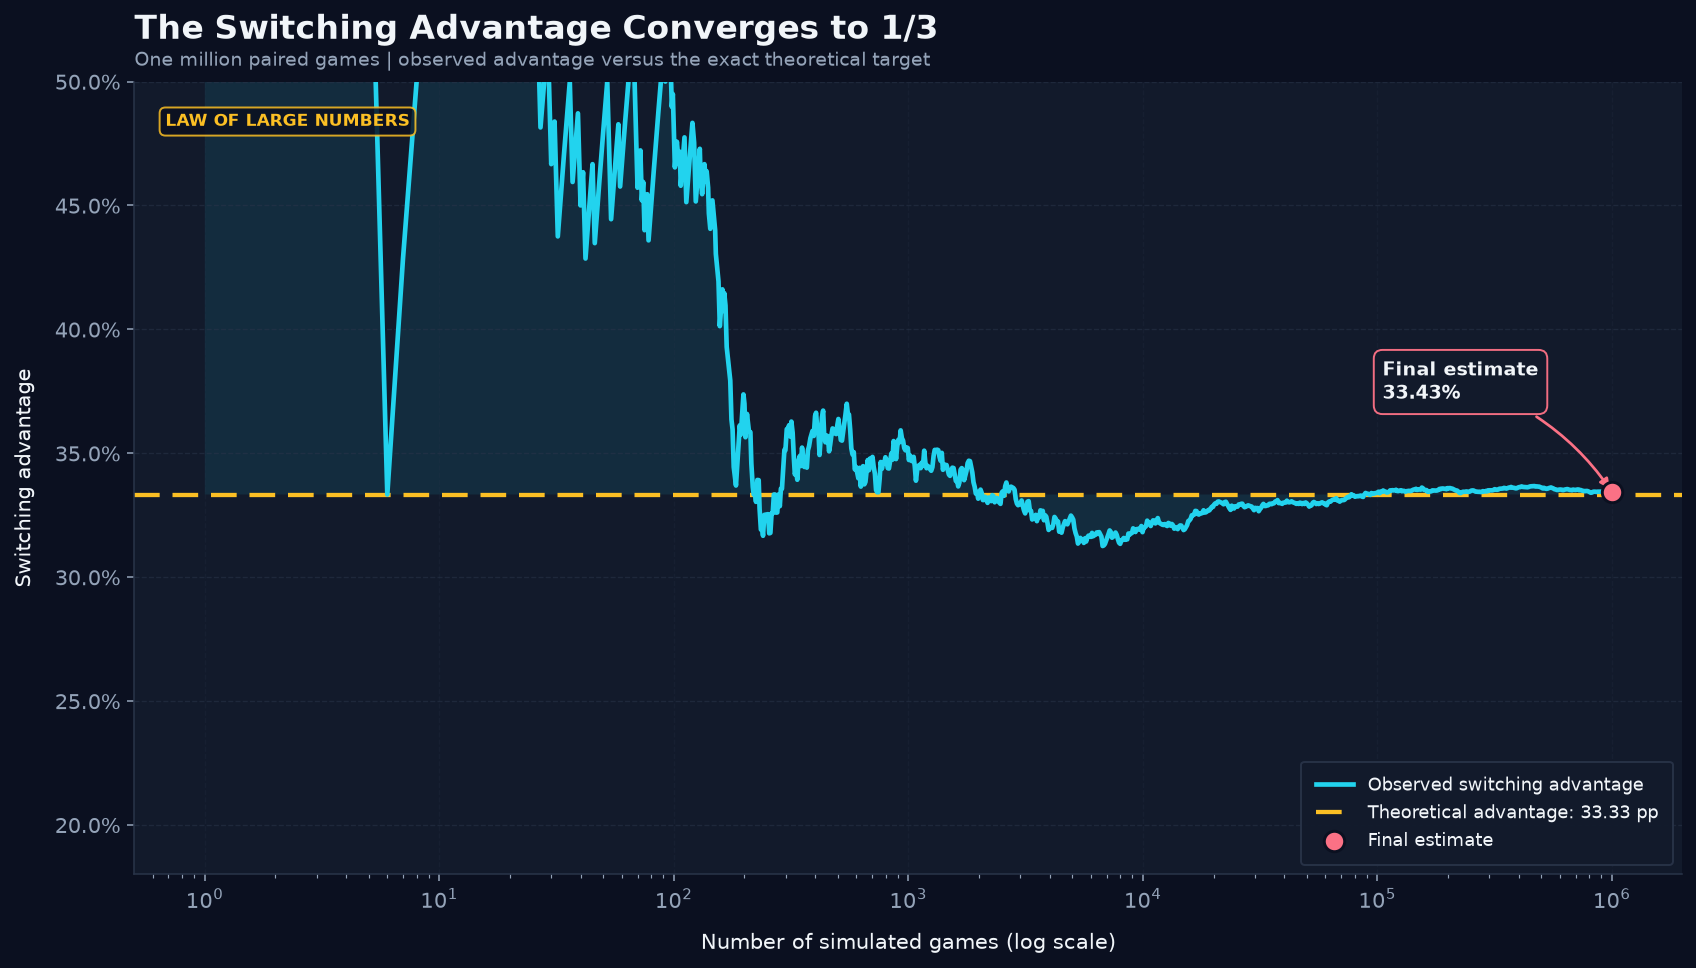

In [30]:
from matplotlib.ticker import PercentFormatter

# Logarithmically spaced observation points
plot_indices = np.unique(
    np.geomspace(
        1,
        N_SIMULATIONS,
        1200
    ).astype(int)
) - 1

x = game_counts[plot_indices]
y = running_advantage[plot_indices]
theoretical_advantage = 1 / 3

fig, ax = plt.subplots(figsize=(12, 6.8), constrained_layout=True)
fig.patch.set_facecolor(COLORS["background"])

# Show the distance from the theoretical target as a visual confidence cue.
ax.fill_between(
    x,
    y,
    theoretical_advantage,
    color=COLORS["cyan"],
    alpha=0.10,
    linewidth=0
)

# Observed switching advantage
ax.plot(
    x,
    y,
    color=COLORS["cyan"],
    linewidth=2.4,
    label="Observed switching advantage",
    zorder=3
)

# Theoretical advantage
ax.axhline(
    theoretical_advantage,
    color=COLORS["gold"],
    linestyle=(0, (6, 3)),
    linewidth=2.2,
    label="Theoretical advantage: 33.33 pp",
    zorder=2
)

# Mark final estimate
ax.scatter(
    N_SIMULATIONS,
    switching_advantage,
    color=COLORS["coral"],
    edgecolor=COLORS["background"],
    linewidth=1.5,
    s=110,
    zorder=5,
    label="Final estimate"
)

ax.annotate(
    f"Final estimate\n{switching_advantage:.2%}",
    xy=(N_SIMULATIONS, switching_advantage),
    xytext=(-118, 48),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "-|>",
        "connectionstyle": "arc3,rad=-0.18",
        "color": COLORS["coral"],
        "lw": 1.4
    },
    fontsize=10,
    fontweight="bold",
    color=COLORS["text"],
    bbox={
        "boxstyle": "round,pad=0.45",
        "facecolor": COLORS["panel"],
        "edgecolor": COLORS["coral"],
        "alpha": 0.96
    }
)

ax.text(
    0.02,
    0.96,
    "LAW OF LARGE NUMBERS",
    transform=ax.transAxes,
    fontsize=8.5,
    fontweight="bold",
    color=COLORS["gold"],
    va="top",
    bbox={
        "boxstyle": "round,pad=0.35",
        "facecolor": COLORS["background"],
        "edgecolor": COLORS["gold"],
        "alpha": 0.85
    }
)

ax.set_xscale("log")
ax.set_title(
    "The Switching Advantage Converges to 1/3",
    loc="left",
    fontsize=17,
    pad=22
)
ax.text(
    0,
    1.02,
    "One million paired games | observed advantage versus the exact theoretical target",
    transform=ax.transAxes,
    fontsize=10,
    color=COLORS["muted"]
)

ax.set_xlabel("Number of simulated games (log scale)", labelpad=10)
ax.set_ylabel("Switching advantage", labelpad=10)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0.18, 0.50)
ax.grid(axis="x", alpha=0.22)
ax.grid(axis="y", alpha=0.55)
ax.legend(loc="lower right", borderpad=0.8)

plt.show()

**Interpreting the Convergence Experiment**

_The convergence plot tracks the difference between the estimated winning probabilities of switching and staying.At small sample sizes, the observed advantage fluctuates considerably because relatively few games have been played._

_As the number of trials increases, these fluctuations become smaller, and the observed advantage stabilizes near the theoretical value of 33.33 percentage points._

_This behaviour is consistent with the law of large numbers.The experiment also illustrates an important distinction between individual outcomes and long-run probabilities.Switching does not guarantee success in any particular game. It improves the probability of success across repeated games._

_A strategy can therefore be mathematically optimal even though it sometimes produces an unsuccessful outcome._

___
## **9. Generalization: The Monty Hall Problem with \(n\) Doors**

Consider a generalized game with \(n\geq3\) doors.
Exactly one door contains a car, while the remaining \(n-1\) doors contain goats.
The contestant selects one door uniformly at random.

The host knows where the car is located and opens \(n-2\) unselected doors containing goats, leaving exactly one alternative unopened door.
The contestant can either stay with the initial selection or switch to the remaining unopened door.

### **Probability of winning by staying**

The initial selection contains the car with probability:

$$
\boxed{P(Win\mid Stay)=\frac{1}{n}}
$$

### **Probability of winning by switching**

The initial selection is incorrect with probability:

$$
P(C\neq P)=\frac{n-1}{n}
$$

Whenever the initial selection is incorrect, the host's constrained actions leave the car behind the only other unopened door.

Therefore:

$$
\boxed{P(Win\mid Switch)=\frac{n-1}{n}}
$$

### **Switching advantage**

The absolute improvement is:

$$
\Delta_n=
\frac{n-1}{n}-\frac{1}{n}
$$

$$
\boxed{\Delta_n=\frac{n-2}{n}}
$$

The ratio of switching success to staying success is:

$$
\frac{P(Win\mid Switch)}{P(Win\mid Stay)}
=
\frac{(n-1)/n}{1/n}
$$

$$
\boxed{\text{Switch-to-stay success ratio}=n-1}
$$

For example:

| Number of doors | Stay | Switch |
|---|---:|---:|
| 3 | 33.33% | 66.67% |
| 5 | 20.00% | 80.00% |
| 10 | 10.00% | 90.00% |
| 20 | 5.00% | 95.00% |
| 100 | 1.00% | 99.00% |

As the number of doors increases, the advantage of switching becomes increasingly pronounced.

This generalization makes the underlying probability structure easier to recognize: the host does not redistribute the initial probability equally between the two unopened doors.

**Generalized simulation**

We can simulate the generalized game without explicitly constructing all the doors.
Why?

Because the final outcomes depend entirely on whether the initial selection was correct.
For each game:

$$
StayWin=\mathbb{1}(C=P)
$$

$$
SwitchWin=\mathbb{1}(C\neq P)
$$

This allows a much more efficient simulation.

In [27]:
def simulate_monty_hall(n_doors, n_trials=100_000, seed=42):
    """
    Simulate the generalized Monty Hall game.

    Assumptions:
    - One car among n doors.
    - Initial selection is uniform.
    - Host reveals n-2 goats.
    - Exactly one alternative unopened door remains.
    """

    if n_doors < 3:
        raise ValueError("At least three doors are required.")

    rng = np.random.default_rng(seed)

    # Random car locations and initial selections
    car = rng.integers(0, n_doors, size=n_trials)
    choice = rng.integers(0, n_doors, size=n_trials)

    # Under the host rules, switching wins exactly
    # when the initial selection is incorrect.
    stay_wins = choice == car
    switch_wins = choice != car

    return {
        "Doors": n_doors,
        "Stay (Simulated)": stay_wins.mean(),
        "Switch (Simulated)": switch_wins.mean(),
        "Stay (Theoretical)": 1 / n_doors,
        "Switch (Theoretical)": (n_doors - 1) / n_doors
    }


door_counts = [3, 5, 10, 20, 50, 100]

generalized_results = pd.DataFrame([
    simulate_monty_hall(n)
    for n in door_counts
])

generalized_results

,Doors,Stay (Simulated),Switch (Simulated),Stay (Theoretical),Switch (Theoretical)
0,3,0.33120,0.66880,0.333333,0.666667
1,5,0.19744,0.80256,0.200000,0.800000
2,10,0.09773,0.90227,0.100000,0.900000
3,20,0.04908,0.95092,0.050000,0.950000
4,50,0.01974,0.98026,0.020000,0.980000
5,100,0.00997,0.99003,0.010000,0.990000


**Generalized probability visualisation**

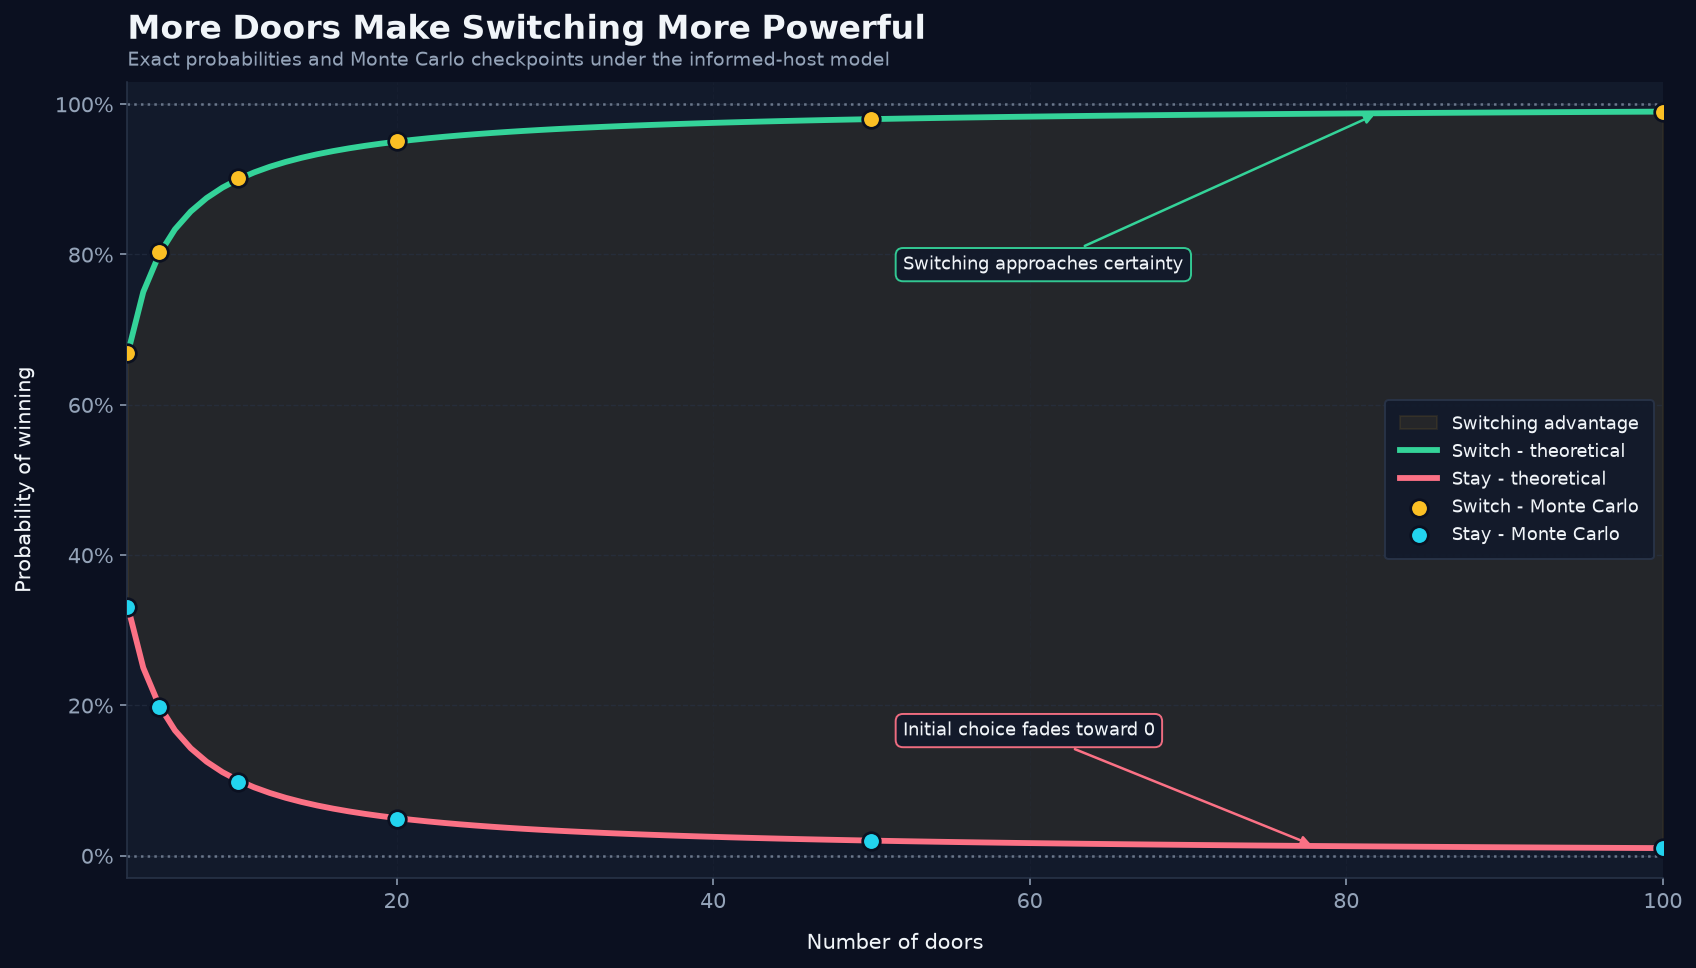

In [31]:
n_values = np.arange(3, 101)

theoretical_stay_curve = 1 / n_values
theoretical_switch_curve = 1 - theoretical_stay_curve

fig, ax = plt.subplots(figsize=(12, 6.8), constrained_layout=True)
fig.patch.set_facecolor(COLORS["background"])

# Highlight the widening probability gap between the two strategies.
ax.fill_between(
    n_values,
    theoretical_stay_curve,
    theoretical_switch_curve,
    color=COLORS["gold"],
    alpha=0.08,
    label="Switching advantage"
)

# Theoretical probability curves
ax.plot(
    n_values,
    theoretical_switch_curve,
    color=COLORS["green"],
    linewidth=3.0,
    label="Switch - theoretical",
    zorder=3
)

ax.plot(
    n_values,
    theoretical_stay_curve,
    color=COLORS["coral"],
    linewidth=3.0,
    label="Stay - theoretical",
    zorder=3
)

# Simulated observations
ax.scatter(
    generalized_results["Doors"],
    generalized_results["Switch (Simulated)"],
    color=COLORS["gold"],
    s=82,
    edgecolor=COLORS["background"],
    linewidth=1.4,
    zorder=5,
    label="Switch - Monte Carlo"
)

ax.scatter(
    generalized_results["Doors"],
    generalized_results["Stay (Simulated)"],
    color=COLORS["cyan"],
    s=82,
    edgecolor=COLORS["background"],
    linewidth=1.4,
    zorder=5,
    label="Stay - Monte Carlo"
)

# Probability limits
ax.axhline(
    1,
    linestyle=":",
    linewidth=1.3,
    color=COLORS["muted"],
    alpha=0.65
)
ax.axhline(
    0,
    linestyle=":",
    linewidth=1.3,
    color=COLORS["muted"],
    alpha=0.65
)

ax.annotate(
    "Switching approaches certainty",
    xy=(82, theoretical_switch_curve[79]),
    xytext=(52, 0.78),
    arrowprops={
        "arrowstyle": "-|>",
        "color": COLORS["green"],
        "lw": 1.3
    },
    color=COLORS["text"],
    fontsize=9.5,
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": COLORS["panel"],
        "edgecolor": COLORS["green"],
        "alpha": 0.94
    }
)

ax.annotate(
    "Initial choice fades toward 0",
    xy=(78, theoretical_stay_curve[75]),
    xytext=(52, 0.16),
    arrowprops={
        "arrowstyle": "-|>",
        "color": COLORS["coral"],
        "lw": 1.3
    },
    color=COLORS["text"],
    fontsize=9.5,
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": COLORS["panel"],
        "edgecolor": COLORS["coral"],
        "alpha": 0.94
    }
)

ax.set_title(
    "More Doors Make Switching More Powerful",
    loc="left",
    fontsize=17,
    pad=22
)
ax.text(
    0,
    1.02,
    "Exact probabilities and Monte Carlo checkpoints under the informed-host model",
    transform=ax.transAxes,
    fontsize=10,
    color=COLORS["muted"]
)

ax.set_xlabel("Number of doors", labelpad=10)
ax.set_ylabel("Probability of winning", labelpad=10)
ax.set_xlim(3, 100)
ax.set_ylim(-0.03, 1.03)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="x", alpha=0.18)
ax.grid(axis="y", alpha=0.55)
ax.legend(loc="center right", borderpad=0.8)

plt.show()

**Interpretation: Why More Doors Strengthen the Switching Strategy**

_The generalized simulation confirms that the advantage of switching increases as the number of doors grows.With three doors, switching wins approximately two-thirds of the time. With ten doors, the theoretical probability increases to 90%. With one hundred doors, switching succeeds with probability 99%._

_This occurs because the initial selection becomes increasingly unlikely to contain the car as the number of doors increases. The host's actions eliminate all but one of the alternative doors without revealing the car._

_Consequently, the remaining alternative inherits the probability associated with the contestant's initially incorrect selection._

_The limiting behaviour is:_

$$
\lim_{n\rightarrow\infty}P(Win\mid Stay)=0
$$

$$
\lim_{n\rightarrow\infty}P(Win\mid Switch)=1
$$

_The generalization demonstrates that the Monty Hall result is not an isolated numerical curiosity associated with three doors.It is a consequence of the relationship between the initial choice, the host's knowledge, and the information revealed through the host's actions._

___

## **11. Key Findings**

The theoretical analysis and Monte Carlo experiments establish several important results.

### **1. Switching is the optimal strategy**

In the classical three-door Monty Hall game:

$$
P(Win\mid Stay)=\frac{1}{3}
$$

$$
P(Win\mid Switch)=\frac{2}{3}
$$

Switching doubles the theoretical probability of winning.

### **2. The simulation closely matches the theoretical model**

Across one million simulated games:

- Staying won 332,838 times.
- Switching won 667,162 times.
- The observed switching advantage was 33.4324 percentage points.

Both estimated probabilities differed from their theoretical values by approximately 0.0495 percentage points.

### **3. Staying and switching are complementary strategies**

Under the specified host rules, exactly one strategy wins in every game.

This produces the identity:

$$
P(Win\mid Stay)+P(Win\mid Switch)=1
$$

The complementarity is an exact mathematical property, not an approximation obtained from simulation.

### **4. Monte Carlo estimates converge toward theoretical probabilities**

As the number of simulated games increases, the estimated switching advantage becomes more stable.
The experiment illustrates the law of large numbers and the distinction between individual outcomes and long-run frequencies.

### **5. The host's behaviour determines the probability structure**

The host's decision is constrained by knowledge of the car's location.
The opened door is therefore not equivalent to a randomly eliminated alternative. The revealed information must be interpreted in the context of the mechanism that generated it.

### **6. The switching advantage generalizes**

For \(n\) doors, with one car and a host who reveals \(n-2\) goats:

$$
P(Win\mid Switch)=\frac{n-1}{n}
$$

As the number of doors increases, the theoretical probability of winning by switching approaches one.

___

## **12. Assumptions and Limitations**

The conclusions in this notebook depend on the rules of the classical Monty Hall problem.
The model assumes:

- The car is placed uniformly among the available doors.
- The contestant's initial selection is independent of the car's location.
- The host knows which door contains the car.
- The host never opens the contestant's selected door.
- The host never reveals the car.
- The host always offers the contestant the opportunity to switch.
- In the generalized game, the host opens all but one of the unselected doors.

If the host follows a different procedure, the resulting conditional probabilities may change.

For example, a host who opens a door without knowing where the car is located may accidentally reveal the car. Conditioning on a goat being revealed then creates a different probability experiment.

Similarly, a host who selectively offers switching opportunities may introduce additional information through that decision.
The classical result therefore should not be interpreted as a universal rule that switching is always advantageous whenever one alternative is eliminated.

It applies to a specific information-generating process.

___

## **13. Conclusion**

The Monty Hall Problem demonstrates how probability can behave differently from immediate intuition.
The central misconception is that two remaining alternatives must necessarily have equal probabilities.

In this experiment, the two unopened doors are not probabilistically equivalent because they reached that state through different processes.

One door was selected without information. The other remained unopened after an informed host deliberately eliminated a losing alternative.
The initial selection retains its one-third probability of containing the car, while switching succeeds whenever that initial selection was incorrect.

Monte Carlo simulation confirms this result across one million independent games, and the generalized experiment demonstrates that the same reasoning extends to games involving many more doors.
Beyond the game itself, the experiment illustrates a broader statistical principle:

> **The information revealed by an observation cannot be interpreted correctly without understanding how that observation was generated.**

This principle is fundamental to conditional probability, Bayesian inference, statistical modelling, and decision-making under uncertainty.

___

_Thanks for reading._

_by_

**Abdur Rahman (Rahven)**